<a href="https://colab.research.google.com/github/VETTOORLIJO/DS_VettoorLijo/blob/master/FraudDetectionTransactions_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [237]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [238]:
df = pd.read_csv('FraudTransactionsDataset.csv')

In [239]:
df

,Transaction_ID,User_ID,Transaction_Amount,Transaction_Type,Timestamp,Account_Balance,Device_Type,Location,Merchant_Category,IP_Address_Flag,...,Daily_Transaction_Count,Avg_Transaction_Amount_7d,Failed_Transaction_Count_7d,Card_Type,Card_Age,Transaction_Distance,Authentication_Method,Risk_Score,Is_Weekend,Fraud_Label
0,TXN_33553,USER_1834,39.79,POS,2023-08-14 19:30:00,93213.17,Laptop,Sydney,Travel,0,...,7,437.63,3,Amex,65,883.17,Biometric,0.8494,0,0
1,TXN_9427,USER_7875,1.19,Bank Transfer,2023-06-07 04:01:00,75725.25,Mobile,New York,Clothing,0,...,13,478.76,4,Mastercard,186,2203.36,Password,0.0959,0,1
2,TXN_199,USER_2734,28.96,Online,2023-06-20 15:25:00,1588.96,Tablet,Mumbai,Restaurants,0,...,14,50.01,4,Visa,226,1909.29,Biometric,0.8400,0,1
3,TXN_12447,USER_2617,254.32,ATM Withdrawal,2023-12-07 00:31:00,76807.20,Tablet,New York,Clothing,0,...,8,182.48,4,Visa,76,1311.86,OTP,0.7935,0,1
4,TXN_39489,USER_2014,31.28,POS,2023-11-11 23:44:00,92354.66,Mobile,Mumbai,Electronics,0,...,14,328.69,4,Mastercard,140,966.98,Password,0.3819,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,TXN_11284,USER_4796,45.05,Online,2023-01-29 18:38:00,76960.11,Mobile,Tokyo,Clothing,0,...,2,389.00,3,Amex,98,1537.54,PIN,0.1493,1,0
49996,TXN_44732,USER_1171,126.15,POS,2023-05-09 08:55:00,28791.75,Mobile,Tokyo,Clothing,0,...,13,434.95,4,Visa,93,2555.72,Biometric,0.3653,0,1
49997,TXN_38158,USER_2510,72.02,Online,2023-01-30 19:32:00,29916.41,Laptop,Mumbai,Clothing,0,...,1,369.15,2,Visa,114,4686.59,Biometric,0.5195,0,0
49998,TXN_860,USER_2248,64.89,Bank Transfer,2023-03-09 19:47:00,67895.67,Mobile,Tokyo,Electronics,0,...,13,242.29,4,Discover,72,4886.92,Biometric,0.7063,0,1


In [240]:
df.describe()

,Transaction_Amount,Account_Balance,IP_Address_Flag,Previous_Fraudulent_Activity,Daily_Transaction_Count,Avg_Transaction_Amount_7d,Failed_Transaction_Count_7d,Card_Age,Transaction_Distance,Risk_Score,Is_Weekend,Fraud_Label
count,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,99.411012,50294.065981,0.05020,0.098400,7.485240,255.271924,2.003540,119.999940,2499.164155,0.501556,0.299640,0.321340
std,98.687292,28760.458557,0.21836,0.297858,4.039637,141.382279,1.414273,68.985817,1442.013834,0.287774,0.458105,0.466996
min,0.000000,500.480000,0.00000,0.000000,1.000000,10.000000,0.000000,1.000000,0.250000,0.000100,0.000000,0.000000
25%,28.677500,25355.995000,0.00000,0.000000,4.000000,132.087500,1.000000,60.000000,1256.497500,0.254000,0.000000,0.000000
50%,69.660000,50384.430000,0.00000,0.000000,7.000000,256.085000,2.000000,120.000000,2490.785000,0.502250,0.000000,0.000000
75%,138.852500,75115.135000,0.00000,0.000000,11.000000,378.032500,3.000000,180.000000,3746.395000,0.749525,1.000000,1.000000
max,1174.140000,99998.310000,1.00000,1.000000,14.000000,500.000000,4.000000,239.000000,4999.930000,1.000000,1.000000,1.000000


In [241]:
df.duplicated().sum()

np.int64(0)

In [242]:
df.isna().sum()

,0
Transaction_ID,0
User_ID,0
Transaction_Amount,0
Transaction_Type,0
Timestamp,0
Account_Balance,0
Device_Type,0
Location,0
Merchant_Category,0
IP_Address_Flag,0


In [243]:
df.dtypes

,0
Transaction_ID,object
User_ID,object
Transaction_Amount,float64
Transaction_Type,object
Timestamp,object
Account_Balance,float64
Device_Type,object
Location,object
Merchant_Category,object
IP_Address_Flag,int64


In [244]:
df["Day_of_Week"], df["Hour"] = (pd.to_datetime(df["Timestamp"]).dt.day_name(),
                                pd.to_datetime(df["Timestamp"]).dt.hour,)  ## chanage to day of the week, and 24 hr

In [245]:
df_num=df.select_dtypes(include=np.number).drop(["Is_Weekend"],axis=1)  # remove it , it is duplicated
df_num

,Transaction_Amount,Account_Balance,IP_Address_Flag,Previous_Fraudulent_Activity,Daily_Transaction_Count,Avg_Transaction_Amount_7d,Failed_Transaction_Count_7d,Card_Age,Transaction_Distance,Risk_Score,Fraud_Label,Hour
0,39.79,93213.17,0,0,7,437.63,3,65,883.17,0.8494,0,19
1,1.19,75725.25,0,0,13,478.76,4,186,2203.36,0.0959,1,4
2,28.96,1588.96,0,0,14,50.01,4,226,1909.29,0.8400,1,15
3,254.32,76807.20,0,0,8,182.48,4,76,1311.86,0.7935,1,0
4,31.28,92354.66,0,1,14,328.69,4,140,966.98,0.3819,1,23
...,...,...,...,...,...,...,...,...,...,...,...,...
49995,45.05,76960.11,0,0,2,389.00,3,98,1537.54,0.1493,0,18
49996,126.15,28791.75,0,0,13,434.95,4,93,2555.72,0.3653,1,8
49997,72.02,29916.41,0,1,1,369.15,2,114,4686.59,0.5195,0,19
49998,64.89,67895.67,0,0,13,242.29,4,72,4886.92,0.7063,1,19


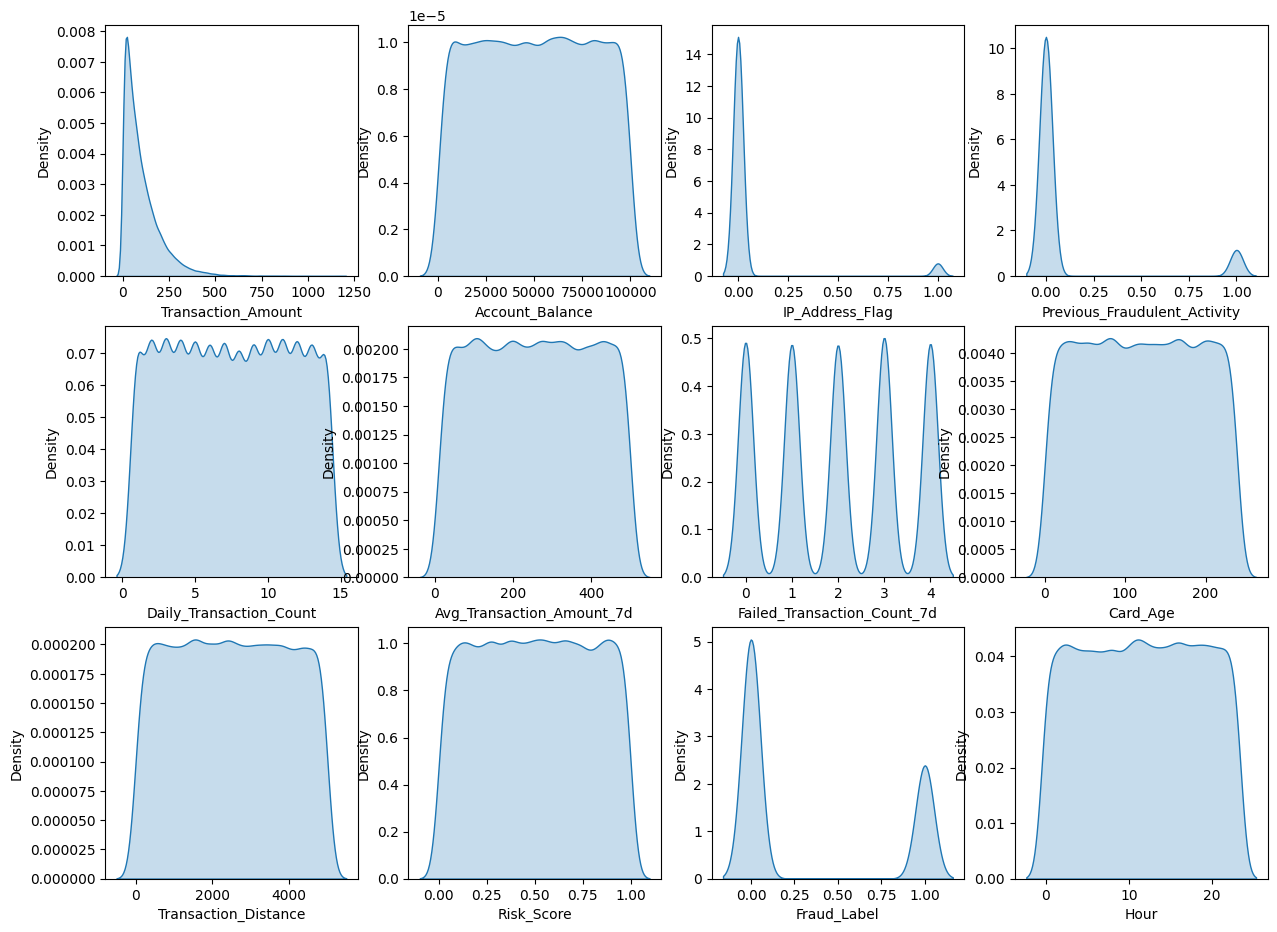

In [246]:
plt.figure(figsize=(15,15))
for i, col in enumerate(df_num.columns):
    plt.subplot(4,4,i+1)
    sns.kdeplot(df_num[col], fill=True)
plt.show()

In [247]:
corr = df_num.corr(numeric_only=True)
corr['Fraud_Label'].sort_values(ascending=False)

,Fraud_Label
Fraud_Label,1.000000
Failed_Transaction_Count_7d,0.509871
Risk_Score,0.385810
Hour,0.005822
IP_Address_Flag,0.003028
Transaction_Amount,0.001901
Avg_Transaction_Amount_7d,0.000703
Transaction_Distance,-0.000116
Previous_Fraudulent_Activity,-0.000718
Card_Age,-0.003120


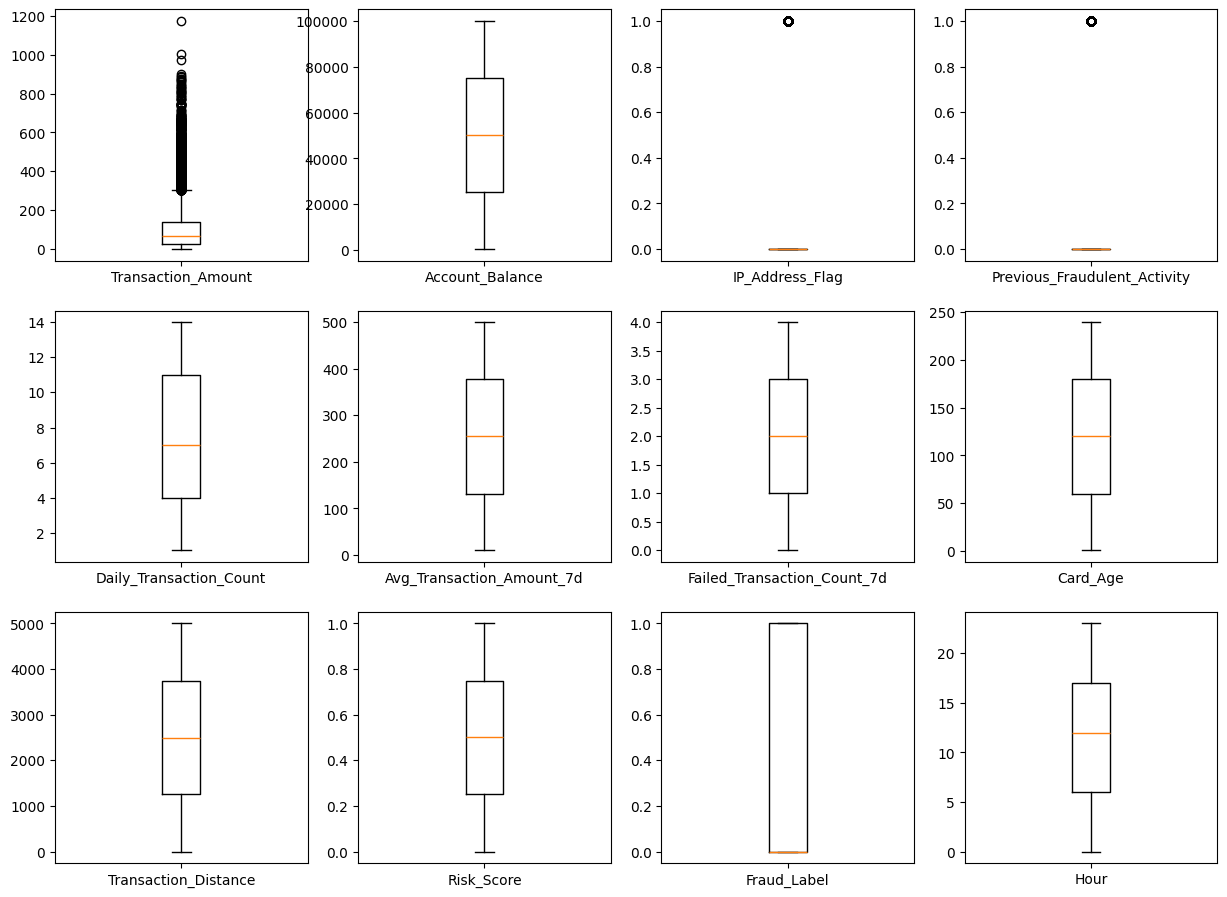

In [248]:
plt.figure(figsize=(15,15))
for i, col in enumerate(df_num.columns):
    plt.subplot(4,4,i+1)
    plt.boxplot(df_num[col],tick_labels=[col])
plt.show()

In [249]:
# plt.figure(figsize=(20,5))
# plt.boxplot(df_num,tick_labels=df_num.columns)
# plt.xticks(rotation=45)
# plt.show()

In [250]:
df.columns

Index(['Transaction_ID', 'User_ID', 'Transaction_Amount', 'Transaction_Type',
       'Timestamp', 'Account_Balance', 'Device_Type', 'Location',
       'Merchant_Category', 'IP_Address_Flag', 'Previous_Fraudulent_Activity',
       'Daily_Transaction_Count', 'Avg_Transaction_Amount_7d',
       'Failed_Transaction_Count_7d', 'Card_Type', 'Card_Age',
       'Transaction_Distance', 'Authentication_Method', 'Risk_Score',
       'Is_Weekend', 'Fraud_Label', 'Day_of_Week', 'Hour'],
      dtype='object')

In [251]:
df_obj=df.select_dtypes(include=object).drop(['Transaction_ID',"User_ID","Timestamp"],axis=1)
df_obj

,Transaction_Type,Device_Type,Location,Merchant_Category,Card_Type,Authentication_Method,Day_of_Week
0,POS,Laptop,Sydney,Travel,Amex,Biometric,Monday
1,Bank Transfer,Mobile,New York,Clothing,Mastercard,Password,Wednesday
2,Online,Tablet,Mumbai,Restaurants,Visa,Biometric,Tuesday
3,ATM Withdrawal,Tablet,New York,Clothing,Visa,OTP,Thursday
4,POS,Mobile,Mumbai,Electronics,Mastercard,Password,Saturday
...,...,...,...,...,...,...,...
49995,Online,Mobile,Tokyo,Clothing,Amex,PIN,Sunday
49996,POS,Mobile,Tokyo,Clothing,Visa,Biometric,Tuesday
49997,Online,Laptop,Mumbai,Clothing,Visa,Biometric,Monday
49998,Bank Transfer,Mobile,Tokyo,Electronics,Discover,Biometric,Thursday


In [252]:
df_obj_encoded=pd.get_dummies(df_obj,drop_first=True,dtype=int)
df_obj_encoded

,Transaction_Type_Bank Transfer,Transaction_Type_Online,Transaction_Type_POS,Device_Type_Mobile,Device_Type_Tablet,Location_Mumbai,Location_New York,Location_Sydney,Location_Tokyo,Merchant_Category_Electronics,...,Card_Type_Visa,Authentication_Method_OTP,Authentication_Method_PIN,Authentication_Method_Password,Day_of_Week_Monday,Day_of_Week_Saturday,Day_of_Week_Sunday,Day_of_Week_Thursday,Day_of_Week_Tuesday,Day_of_Week_Wednesday
0,0,0,1,0,0,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,0
1,1,0,0,1,0,0,1,0,0,0,...,0,0,0,1,0,0,0,0,0,1
2,0,1,0,0,1,1,0,0,0,0,...,1,0,0,0,0,0,0,0,1,0
3,0,0,0,0,1,0,1,0,0,0,...,1,1,0,0,0,0,0,1,0,0
4,0,0,1,1,0,1,0,0,0,1,...,0,0,0,1,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,0,1,0,1,0,0,0,0,1,0,...,0,0,1,0,0,0,1,0,0,0
49996,0,0,1,1,0,0,0,0,1,0,...,1,0,0,0,0,0,0,0,1,0
49997,0,1,0,0,0,1,0,0,0,0,...,1,0,0,0,1,0,0,0,0,0
49998,1,0,0,1,0,0,0,0,1,1,...,0,0,0,0,0,0,0,1,0,0


In [253]:
df_final = pd.concat([df_num,df_obj_encoded],axis=1)
df_final.dtypes

,0
Transaction_Amount,float64
Account_Balance,float64
IP_Address_Flag,int64
Previous_Fraudulent_Activity,int64
Daily_Transaction_Count,int64
Avg_Transaction_Amount_7d,float64
Failed_Transaction_Count_7d,int64
Card_Age,int64
Transaction_Distance,float64
Risk_Score,float64


In [254]:
from sklearn.model_selection import train_test_split
X=df_final.drop("Fraud_Label",axis=1)
y=df_final["Fraud_Label"]
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)
result=[]

In [255]:
y_test.value_counts()

,count
Fraud_Label,
0,6765
1,3235


In [256]:
y_train.value_counts()

,count
Fraud_Label,
0,27168
1,12832


In [257]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,
                                                    random_state=42,
                                                    stratify=y)

In [258]:
y_test.value_counts()

,count
Fraud_Label,
0,6787
1,3213


In [259]:
y_train.value_counts()

,count
Fraud_Label,
0,27146
1,12854


In [260]:
def eval_result(y_test,y_pred,model_name):
    result.append({
        "model": model_name,
        "accuracy_score": round(accuracy_score(y_test, y_pred), 4),
        "precision_score": round(precision_score(y_test, y_pred), 4),
        "recall_score": round(recall_score(y_test, y_pred), 4),
        "f1_score": round(f1_score(y_test, y_pred), 4),
        "confusion_matrix": confusion_matrix(y_test, y_pred)
    })
    return pd.DataFrame(result)

In [261]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.transform(X_test)

In [262]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix,precision_score,recall_score,f1_score
l_r=LogisticRegression()
l_r.fit(X_train_scaled,y_train)
y_pred=l_r.predict(X_test_scaled)
print(accuracy_score(y_test,y_pred))

0.7995


In [263]:
results_df = eval_result(y_test,y_pred,"Logistic Regression")

In [264]:
results_df

,model,accuracy_score,precision_score,recall_score,f1_score,confusion_matrix
0,Logistic Regression,0.7995,0.7061,0.6439,0.6736,"[[5926, 861], [1144, 2069]]"
